In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn jupyter

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load dataset
df = pd.read_csv("TaxiFare.csv")

# Display first five records
df.head()

,unique_id,date_time_of_pickup,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
0,26:21.0,2009-06-15 17:26:21 UTC,-73.844311,40.721319,-73.841610,40.712278,1,4.5
1,52:16.0,2010-01-05 16:52:16 UTC,-74.016048,40.711303,-73.979268,40.782004,1,16.9
2,35:00.0,2011-08-18 00:35:00 UTC,-73.982738,40.761270,-73.991242,40.750562,2,5.7
3,30:42.0,2012-04-21 04:30:42 UTC,-73.987130,40.733143,-73.991567,40.758092,1,7.7
4,51:00.0,2010-03-09 07:51:00 UTC,-73.968095,40.768008,-73.956655,40.783762,1,5.3


In [4]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (50000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   unique_id             50000 non-null  object 
 1   date_time_of_pickup   50000 non-null  object 
 2   longitude_of_pickup   50000 non-null  float64
 3   latitude_of_pickup    50000 non-null  float64
 4   longitude_of_dropoff  50000 non-null  float64
 5   latitude_of_dropoff   50000 non-null  float64
 6   no_of_passenger       50000 non-null  int64  
 7   amount                50000 non-null  float64
dtypes: float64(5), int64(1), object(2)
memory usage: 3.1+ MB


,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,-72.509756,39.933759,-72.504616,39.926251,1.667840,11.364171
std,10.393860,6.224857,10.407570,6.014737,1.289195,9.685557
min,-75.423848,-74.006893,-84.654241,-74.006377,0.000000,-5.000000
25%,-73.992062,40.734880,-73.991152,40.734372,1.000000,6.000000
50%,-73.981840,40.752678,-73.980082,40.753372,1.000000,8.500000
75%,-73.967148,40.767360,-73.963584,40.768167,2.000000,12.500000
max,40.783472,401.083332,40.851027,43.415190,6.000000,200.000000


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique values
print("\nUnique Values:")
print(df.nunique())

Missing Values:
unique_id               0
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
dtype: int64

Duplicate Rows: 0

Unique Values:
unique_id                3597
date_time_of_pickup     49555
longitude_of_pickup     33716
latitude_of_pickup      36594
longitude_of_dropoff    34878
latitude_of_dropoff     37423
no_of_passenger             7
amount                    703
dtype: int64


In [6]:
# Check unique ID distribution
print("Total records:", len(df))
print("Unique IDs:", df['unique_id'].nunique())

# Find repeated IDs
print("\nMost repeated IDs:")
print(df['unique_id'].value_counts().head(10))

# Count records with repeated IDs
print("\nRepeated ID records:",
      df['unique_id'].duplicated().sum())

# Display sample records
df[['unique_id', 'date_time_of_pickup']].head(10)

Total records: 50000
Unique IDs: 3597

Most repeated IDs:
unique_id
26:00.0    457
33:00.0    439
11:00.0    436
32:00.0    429
20:00.0    424
22:00.0    423
14:00.0    416
13:00.0    411
56:00.0    410
45:00.0    410
Name: count, dtype: int64

Repeated ID records: 46403


,unique_id,date_time_of_pickup
0,26:21.0,2009-06-15 17:26:21 UTC
1,52:16.0,2010-01-05 16:52:16 UTC
2,35:00.0,2011-08-18 00:35:00 UTC
3,30:42.0,2012-04-21 04:30:42 UTC
4,51:00.0,2010-03-09 07:51:00 UTC
5,50:45.0,2011-01-06 09:50:45 UTC
6,35:00.0,2012-11-20 20:35:00 UTC
7,22:00.0,2012-01-04 17:22:00 UTC
8,10:00.0,2012-12-03 13:10:00 UTC
9,11:00.0,2009-09-02 01:11:00 UTC


In [7]:
# Convert pickup datetime to datetime format
df['date_time_of_pickup'] = pd.to_datetime(
    df['date_time_of_pickup'],
    errors='coerce',
    utc=True
)

# Check data type
print("Data Type:", df['date_time_of_pickup'].dtype)

# Check invalid datetime values
print("Invalid Datetimes:",
      df['date_time_of_pickup'].isnull().sum())

# Display date range
print("Earliest Pickup:", df['date_time_of_pickup'].min())
print("Latest Pickup:", df['date_time_of_pickup'].max())

Data Type: datetime64[ns, UTC]
Invalid Datetimes: 0
Earliest Pickup: 2009-01-01 01:31:49+00:00
Latest Pickup: 2015-06-30 22:42:39+00:00


In [8]:
# Define approximate NYC region
invalid_pickup = (
    ~df['longitude_of_pickup'].between(-75.5, -71.5) |
    ~df['latitude_of_pickup'].between(39.5, 42.5)
)

invalid_dropoff = (
    ~df['longitude_of_dropoff'].between(-75.5, -71.5) |
    ~df['latitude_of_dropoff'].between(39.5, 42.5)
)

print("Invalid Pickup Coordinates:", invalid_pickup.sum())

print("Invalid Dropoff Coordinates:", invalid_dropoff.sum())

print("Rows with Invalid Coordinates:",
      (invalid_pickup | invalid_dropoff).sum())

# Display suspicious records
df.loc[
    invalid_pickup | invalid_dropoff,
    ['longitude_of_pickup', 'latitude_of_pickup',
     'longitude_of_dropoff', 'latitude_of_dropoff']
].head(10)

Invalid Pickup Coordinates: 984
Invalid Dropoff Coordinates: 986
Rows with Invalid Coordinates: 1031


,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff
11,0.0,0.0,0.0,0.0
15,0.0,0.0,0.0,0.0
26,0.0,0.0,0.0,0.0
124,0.0,0.0,0.0,0.0
192,0.0,0.0,0.0,0.0
233,0.0,0.0,0.0,0.0
273,0.0,0.0,0.0,0.0
357,0.0,0.0,0.0,0.0
376,0.0,0.0,0.0,0.0
387,0.0,0.0,0.0,0.0


In [9]:
# Fare analysis
print("Fare Statistics:")
print(df['amount'].describe())

print("\nNegative Fare Records:",
      (df['amount'] < 0).sum())

print("Zero Fare Records:",
      (df['amount'] == 0).sum())

print("Fare Above $100:",
      (df['amount'] > 100).sum())

# Passenger analysis
print("\nPassenger Count Distribution:")
print(df['no_of_passenger'].value_counts().sort_index())

print("\nZero Passenger Records:",
      (df['no_of_passenger'] == 0).sum())

Fare Statistics:
count    50000.000000
mean        11.364171
std          9.685557
min         -5.000000
25%          6.000000
50%          8.500000
75%         12.500000
max        200.000000
Name: amount, dtype: float64

Negative Fare Records: 6
Zero Fare Records: 3
Fare Above $100: 16

Passenger Count Distribution:
no_of_passenger
0      165
1    34808
2     7386
3     2183
4     1016
5     3453
6      989
Name: count, dtype: int64

Zero Passenger Records: 165


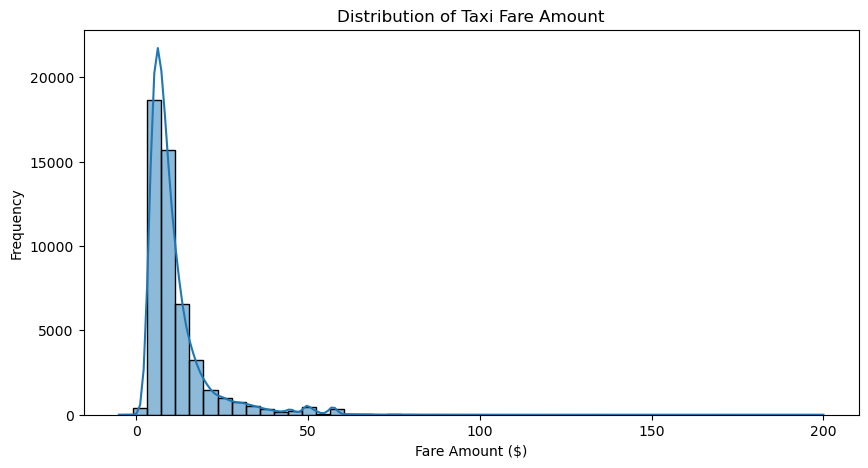

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(df['amount'], bins=50, kde=True)

plt.title("Distribution of Taxi Fare Amount")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Frequency")

plt.show()

In [11]:
# Display fares above $100
high_fare_records = df[df['amount'] > 100]

print("High Fare Records:", len(high_fare_records))

display(high_fare_records[
    ['date_time_of_pickup',
     'longitude_of_pickup',
     'latitude_of_pickup',
     'longitude_of_dropoff',
     'latitude_of_dropoff',
     'no_of_passenger',
     'amount']
])

High Fare Records: 16


,date_time_of_pickup,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
1335,2013-01-16 20:19:58+00:00,-74.429332,40.500046,-74.429332,40.500046,1,180.00
1483,2009-08-07 21:49:13+00:00,-73.633363,41.032490,-73.633671,41.032598,1,165.00
6630,2014-05-16 01:51:00+00:00,0.000000,0.000000,0.000000,0.000000,1,128.83
12349,2010-05-01 15:23:00+00:00,-73.797225,40.639720,-73.840545,41.030892,1,104.67
14142,2014-12-12 10:13:00+00:00,-74.013570,40.705930,-74.000740,40.738960,1,108.00
20886,2010-07-17 17:34:16+00:00,-73.739901,40.956220,-73.739901,40.956220,2,120.00
25201,2013-12-16 10:56:58+00:00,-73.424988,40.779894,-73.423209,40.782906,1,135.00
25799,2014-02-07 03:35:00+00:00,-73.988032,40.731992,-73.988023,40.731960,1,110.00
26027,2014-08-14 20:22:14+00:00,-73.855030,40.729882,-73.855039,40.729884,4,149.00
28373,2012-02-26 03:24:00+00:00,-73.954922,41.391042,-73.954918,41.391042,1,200.00


In [12]:
# Haversine distance calculation
def haversine_distance(lat1, lon1, lat2, lon2):

    # Convert degrees into radians
    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    # Differences
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Haversine formula
    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    # Earth's radius in kilometers
    R = 6371

    distance = 2 * R * np.arcsin(np.sqrt(a))

    return distance

In [13]:
high_fare_records = df[df['amount'] > 100].copy()

high_fare_records['trip_distance'] = high_fare_records.apply(
    lambda row: haversine_distance(
        row['latitude_of_pickup'],
        row['longitude_of_pickup'],
        row['latitude_of_dropoff'],
        row['longitude_of_dropoff']
    ),
    axis=1
)

display(
    high_fare_records[
        ['amount', 'trip_distance', 'no_of_passenger']
    ].sort_values('trip_distance')
)

,amount,trip_distance,no_of_passenger
1335,180.00,0.000000,1
6630,128.83,0.000000,1
20886,120.00,0.000000,2
42756,143.00,0.000000,1
28373,200.00,0.000334,1
26027,149.00,0.000790,4
25799,110.00,0.003638,1
1483,165.00,0.028489,1
37215,128.61,0.080989,5
25201,135.00,0.366888,1


In [14]:
# Create a copy of original dataset
df_clean = df.copy()

# 1. Check valid pickup coordinates
valid_pickup = (
    df_clean['longitude_of_pickup'].between(-75.5, -71.5) &
    df_clean['latitude_of_pickup'].between(39.5, 42.5)
)

# 2. Check valid dropoff coordinates
valid_dropoff = (
    df_clean['longitude_of_dropoff'].between(-75.5, -71.5) &
    df_clean['latitude_of_dropoff'].between(39.5, 42.5)
)

# 3. Check valid fare
valid_fare = df_clean['amount'] > 0

# 4. Check valid passenger count
valid_passengers = df_clean['no_of_passenger'] > 0

# Combine all conditions
valid_records = (
    valid_pickup &
    valid_dropoff &
    valid_fare &
    valid_passengers
)

# Display individual invalid counts
print("Invalid Pickup Coordinates:", (~valid_pickup).sum())
print("Invalid Dropoff Coordinates:", (~valid_dropoff).sum())
print("Invalid Fares:", (~valid_fare).sum())
print("Invalid Passenger Counts:", (~valid_passengers).sum())

# Apply cleaning
df_clean = df_clean[valid_records].copy()

print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)
print("Total Rows Removed:", len(df) - len(df_clean))

Invalid Pickup Coordinates: 984
Invalid Dropoff Coordinates: 986
Invalid Fares: 9
Invalid Passenger Counts: 165

Original Dataset Shape: (50000, 8)
Cleaned Dataset Shape: (48802, 8)
Total Rows Removed: 1198


In [15]:
# Remove unique_id because it is not a genuine trip identifier
df_clean.drop(columns=['unique_id'], inplace=True)

print("Columns after removal:")
print(df_clean.columns.tolist())

Columns after removal:
['date_time_of_pickup', 'longitude_of_pickup', 'latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff', 'no_of_passenger', 'amount']


In [16]:
# Check dataset information
df_clean.info()

# Check missing values
print("\nMissing Values:")
print(df_clean.isnull().sum())

# Check duplicates
print("\nDuplicate Rows:", df_clean.duplicated().sum())

# Statistical summary
display(df_clean.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 48802 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   date_time_of_pickup   48802 non-null  datetime64[ns, UTC]
 1   longitude_of_pickup   48802 non-null  float64            
 2   latitude_of_pickup    48802 non-null  float64            
 3   longitude_of_dropoff  48802 non-null  float64            
 4   latitude_of_dropoff   48802 non-null  float64            
 5   no_of_passenger       48802 non-null  int64              
 6   amount                48802 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(5), int64(1)
memory usage: 3.0 MB

Missing Values:
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
dtype: int64

Duplicate Rows: 0


,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
count,48802.000000,48802.000000,48802.000000,48802.000000,48802.000000,48802.000000
mean,-73.975213,40.750922,-73.974009,40.751451,1.674624,11.366304
std,0.041553,0.035448,0.039426,0.036776,1.288670,9.661178
min,-75.423848,39.603178,-75.354559,39.604971,1.000000,0.010000
25%,-73.992308,40.736500,-73.991332,40.735904,1.000000,6.000000
50%,-73.982121,40.753445,-73.980483,40.754120,1.000000,8.500000
75%,-73.968369,40.767771,-73.965328,40.768481,2.000000,12.500000
max,-72.856968,42.160275,-72.854940,42.168717,6.000000,200.000000


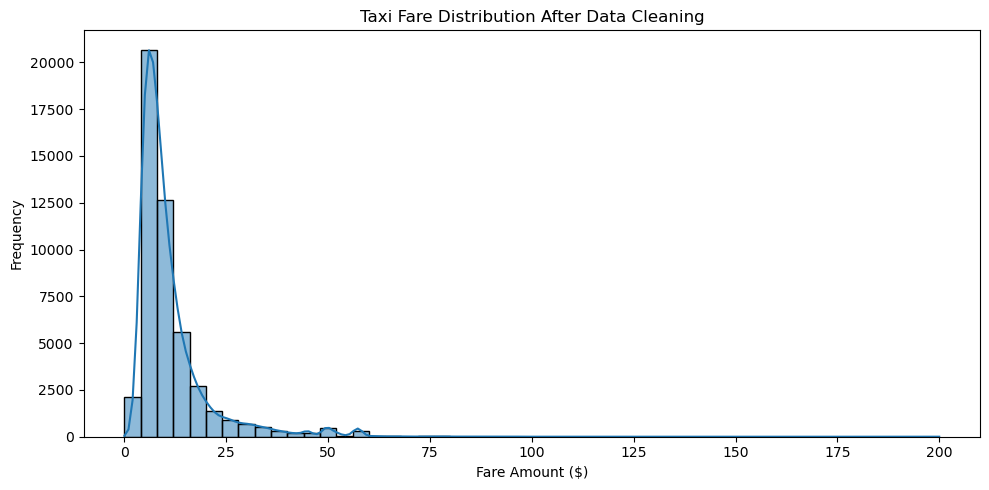

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['amount'],
    bins=50,
    kde=True
)

plt.title("Taxi Fare Distribution After Data Cleaning")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
# Calculate Haversine distance for every trip

lat1 = np.radians(df_clean['latitude_of_pickup'])
lon1 = np.radians(df_clean['longitude_of_pickup'])

lat2 = np.radians(df_clean['latitude_of_dropoff'])
lon2 = np.radians(df_clean['longitude_of_dropoff'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2)**2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2)**2
)

df_clean['trip_distance'] = (
    2 * 6371 * np.arcsin(np.sqrt(a))
)

# Identify suspicious high-fare trips
suspicious_fares = (
    (df_clean['amount'] > 100) &
    (df_clean['trip_distance'] < 5)
)

# Display suspicious records before removal
print("Suspicious Records:", suspicious_fares.sum())

display(
    df_clean.loc[
        suspicious_fares,
        ['amount', 'trip_distance', 'no_of_passenger']
    ]
)

# Remove suspicious records
df_clean = df_clean.loc[~suspicious_fares].copy()

print("\nRecords after removing suspicious fares:",
      len(df_clean))

print("Remaining high-fare records:",
      (df_clean['amount'] > 100).sum())

Suspicious Records: 12


,amount,trip_distance,no_of_passenger
1335,180.00,0.000000,1
1483,165.00,0.028489,1
14142,108.00,3.828609,1
20886,120.00,0.000000,2
25201,135.00,0.366888,1
25799,110.00,0.003638,1
26027,149.00,0.000790,4
28373,200.00,0.000334,1
37215,128.61,0.080989,5
42756,143.00,0.000000,1



Records after removing suspicious fares: 48790
Remaining high-fare records: 3


In [19]:
# Final dataset verification

print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nInvalid Fare Records:",
      (df_clean['amount'] <= 0).sum())

print("Invalid Passenger Records:",
      (df_clean['no_of_passenger'] <= 0).sum())

print("Invalid Pickup Coordinates:",
      (
          ~df_clean['longitude_of_pickup'].between(-75.5, -71.5) |
          ~df_clean['latitude_of_pickup'].between(39.5, 42.5)
      ).sum())

print("\nFare Statistics:")
display(df_clean['amount'].describe())

Final Dataset Shape: (48790, 8)

Missing Values:
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
trip_distance           0
dtype: int64

Invalid Fare Records: 0
Invalid Passenger Records: 0
Invalid Pickup Coordinates: 0

Fare Statistics:


count    48790.000000
mean        11.332953
std          9.415758
min          0.010000
25%          6.000000
50%          8.500000
75%         12.500000
max        136.000000
Name: amount, dtype: float64

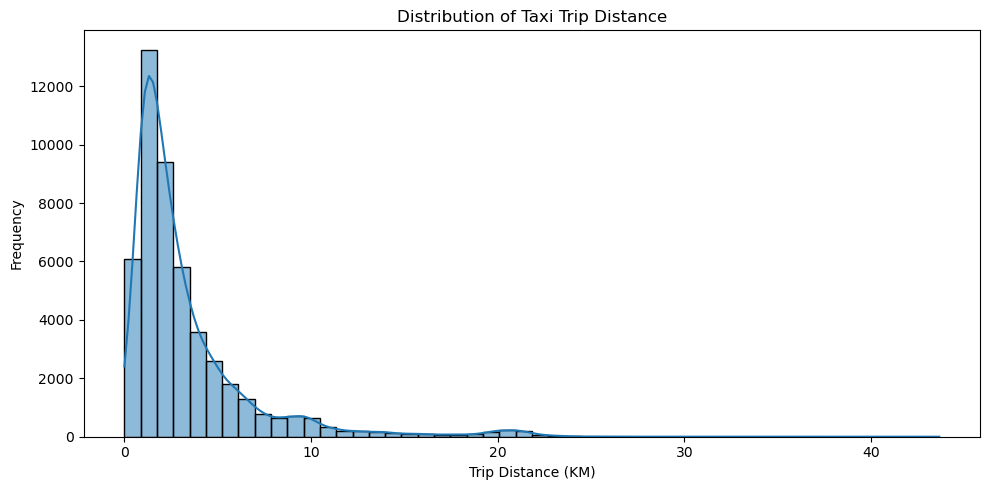

In [76]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['trip_distance'],
    bins=50,
    kde=True
)

plt.title("Distribution of Taxi Trip Distance")
plt.xlabel("Trip Distance (KM)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

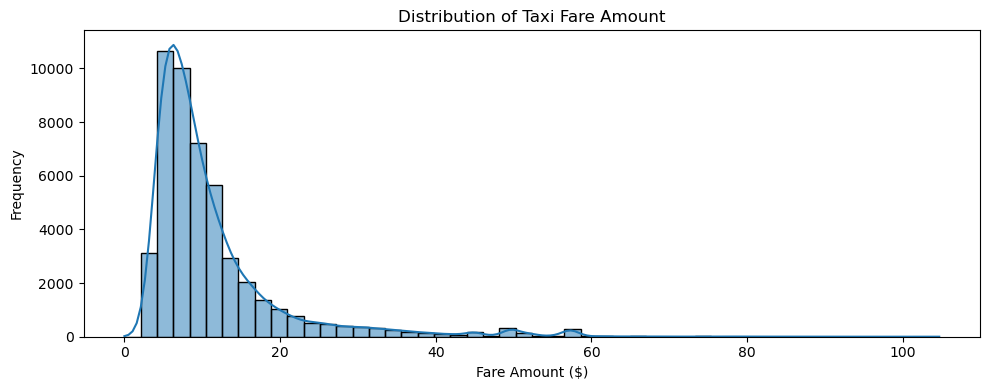

In [72]:
plt.figure(figsize=(10, 4))

sns.histplot(
    df_clean['amount'],
    bins=50,
    kde=True
)

plt.title("Distribution of Taxi Fare Amount")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

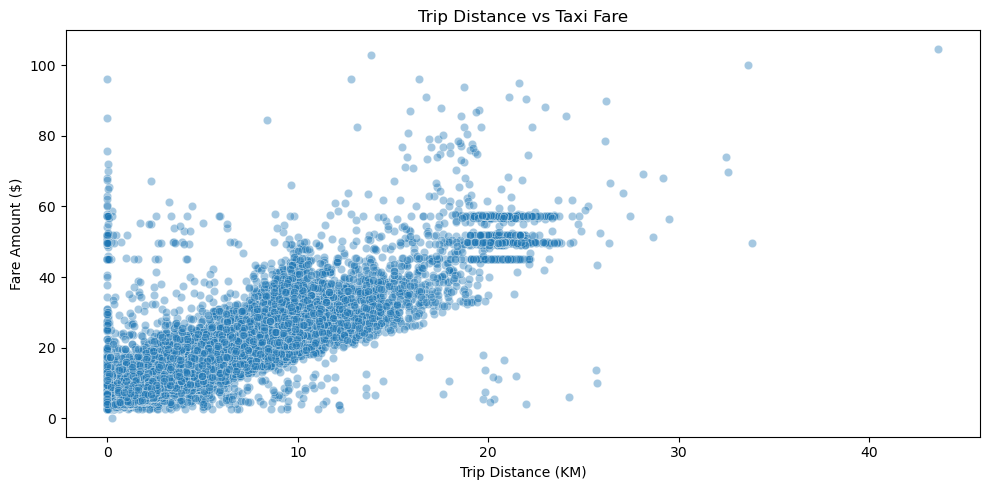

In [74]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='trip_distance',
    y='amount',
    alpha=0.4
)

plt.title("Trip Distance vs Taxi Fare")
plt.xlabel("Trip Distance (KM)")
plt.ylabel("Fare Amount ($)")

plt.tight_layout()
plt.show()

In [25]:
print("Trip Distance Statistics:")
display(df_clean['trip_distance'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

Trip Distance Statistics:


count    48790.000000
mean         3.384521
std          4.333698
min          0.000000
25%          1.263511
50%          2.159961
75%          3.942365
90%          7.062096
95%         10.054507
99%         20.494256
max        164.874362
Name: trip_distance, dtype: float64

In [26]:
print("Zero Distance Trips:",
      (df_clean['trip_distance'] == 0).sum())

print("Trips Below 0.1 KM:",
      (df_clean['trip_distance'] < 0.1).sum())

print("Trips Above 25 KM:",
      (df_clean['trip_distance'] > 25).sum())

print("Trips Above 50 KM:",
      (df_clean['trip_distance'] > 50).sum())

print("Trips Above 100 KM:",
      (df_clean['trip_distance'] > 100).sum())

Zero Distance Trips: 531
Trips Below 0.1 KM: 827
Trips Above 25 KM: 51
Trips Above 50 KM: 25
Trips Above 100 KM: 13


In [27]:
long_trips = df_clean.nlargest(
    15, 'trip_distance'
)

display(
    long_trips[
        ['trip_distance', 'amount', 'no_of_passenger',
         'date_time_of_pickup']
    ]
)

,trip_distance,amount,no_of_passenger,date_time_of_pickup
46482,164.874362,45.00,1,2011-03-18 17:35:27+00:00
10710,129.950482,3.70,1,2011-02-11 21:46:09+00:00
14536,129.560455,4.10,1,2011-04-03 12:16:46+00:00
30950,128.286961,8.50,1,2011-04-25 08:57:38+00:00
37038,127.916598,8.10,1,2011-03-10 16:05:27+00:00
11619,127.509261,11.30,1,2011-05-27 21:47:44+00:00
29654,127.198854,7.70,1,2011-02-10 02:22:52+00:00
44777,127.134200,7.70,1,2011-03-28 12:08:51+00:00
12228,123.561157,16.50,2,2011-04-26 23:18:56+00:00
49003,122.230734,28.10,1,2011-02-23 15:54:03+00:00


                 trip_distance    amount  no_of_passenger
trip_distance         1.000000  0.732127         0.008797
amount                0.732127  1.000000         0.016231
no_of_passenger       0.008797  0.016231         1.000000


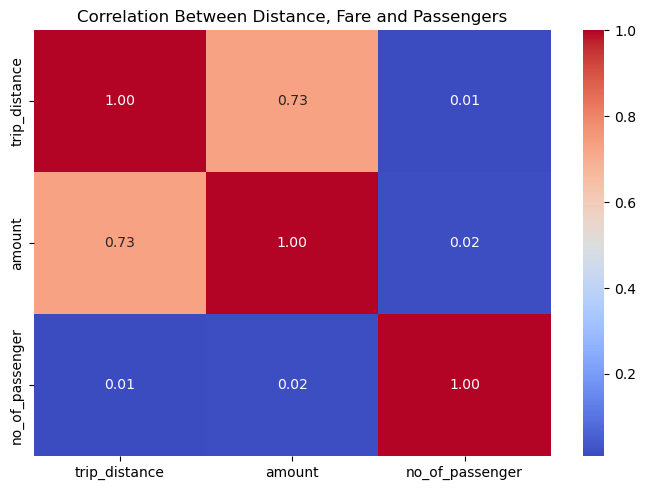

In [28]:
correlation = df_clean[
    ['trip_distance', 'amount', 'no_of_passenger']
].corr()

print(correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Distance, Fare and Passengers")

plt.tight_layout()
plt.show()

In [29]:
long_trips = df_clean.nlargest(20, 'trip_distance')

display(
    long_trips[
        [
            'longitude_of_pickup',
            'latitude_of_pickup',
            'longitude_of_dropoff',
            'latitude_of_dropoff',
            'trip_distance',
            'amount',
            'no_of_passenger'
        ]
    ]
)

,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,trip_distance,amount,no_of_passenger
46482,-75.336082,40.646409,-73.953539,39.606622,164.874362,45.00,1
10710,-73.955411,39.604164,-73.955647,40.772837,129.950482,3.70,1
14536,-73.982155,40.775187,-73.976399,39.610030,129.560455,4.10,1
30950,-73.954724,39.613492,-73.954297,40.767204,128.286961,8.50,1
37038,-73.949891,39.620362,-73.954676,40.770738,127.916598,8.10,1
11619,-73.945106,39.603178,-73.976636,40.749643,127.509261,11.30,1
29654,-73.964531,39.631717,-73.982297,40.775564,127.198854,7.70,1
44777,-73.978483,39.607752,-73.980734,40.751096,127.134200,7.70,1
12228,-73.993360,40.721749,-73.977370,39.610604,123.561157,16.50,2
49003,-75.423848,40.773949,-73.972680,40.755742,122.230734,28.10,1


In [30]:
zero_distance_trips = df_clean[
    df_clean['trip_distance'] == 0
]

print("Zero Distance Records:", len(zero_distance_trips))

print("\nFare Statistics:")
display(zero_distance_trips['amount'].describe())

print("\nSample Zero Distance Records:")

display(
    zero_distance_trips[
        ['trip_distance', 'amount', 'no_of_passenger']
    ].head(15)
)

Zero Distance Records: 531

Fare Statistics:


count    531.000000
mean      10.456949
std       12.700463
min        2.500000
25%        4.700000
50%        6.500000
75%        9.400000
max       96.000000
Name: amount, dtype: float64


Sample Zero Distance Records:


,trip_distance,amount,no_of_passenger
105,0.0,52.00,1
191,0.0,6.50,1
270,0.0,7.50,1
290,0.0,6.90,1
396,0.0,12.00,1
503,0.0,2.50,1
657,0.0,2.50,1
737,0.0,57.33,2
808,0.0,6.10,1
843,0.0,5.50,1


In [31]:
df_clean['fare_per_km'] = (
    df_clean['amount'] /
    df_clean['trip_distance'].replace(0, np.nan)
)

print("Fare per KM Statistics:")
display(df_clean['fare_per_km'].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
))

Fare per KM Statistics:


count     48259.000000
mean         90.956834
std        4921.193287
min           0.025057
50%           3.816077
90%           6.782981
95%           8.549271
99%          23.787712
max      679523.202817
Name: fare_per_km, dtype: float64

In [32]:
# Check frequency of the suspicious coordinate
suspicious_location = df_clean[
    (df_clean['longitude_of_pickup'] == -73.137393) |
    (df_clean['longitude_of_dropoff'] == -73.137393)
]

print("Records involving suspicious location:",
      len(suspicious_location))

display(suspicious_location[
    ['longitude_of_pickup', 'latitude_of_pickup',
     'longitude_of_dropoff', 'latitude_of_dropoff',
     'trip_distance', 'amount']
].head(20))

Records involving suspicious location: 21


,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,trip_distance,amount
1684,-73.137393,41.366138,-73.996510,40.745320,99.771579,2.50
3075,-73.137393,41.366138,-73.974598,40.751311,97.985088,6.90
4487,-73.137393,41.366138,-73.957685,40.765644,95.852036,4.90
5648,-73.137393,41.366138,-73.137393,41.366138,0.000000,7.70
5663,-73.137393,41.366138,-74.000940,40.731723,101.094619,49.15
6416,-73.137393,41.366138,-73.137393,41.366138,0.000000,6.10
7043,-73.137393,41.366138,-73.137393,41.366138,0.000000,3.30
7401,-73.900571,40.764047,-73.137393,41.366138,92.605848,4.50
9808,-73.137393,41.366138,-73.952331,40.786380,93.925599,6.90
9899,-73.974361,40.755168,-73.137393,41.366138,97.670590,7.70


In [33]:
# Inspect zero-distance trips with fares above $20
zero_distance_high_fare = df_clean[
    (df_clean['trip_distance'] == 0) &
    (df_clean['amount'] > 20)
]

print("Zero-distance trips above $20:",
      len(zero_distance_high_fare))

display(zero_distance_high_fare[
    ['amount', 'no_of_passenger',
     'date_time_of_pickup']
].sort_values('amount', ascending=False))

Zero-distance trips above $20: 50


,amount,no_of_passenger,date_time_of_pickup
12915,96.00,1,2011-09-07 01:14:49+00:00
18150,85.00,1,2011-12-22 22:45:37+00:00
10524,75.80,1,2010-05-04 14:12:00+00:00
41621,67.50,1,2010-05-13 20:45:00+00:00
2346,63.00,1,2009-02-07 00:14:00+00:00
44725,62.00,1,2012-11-28 01:43:42+00:00
30923,60.50,1,2011-11-09 20:39:08+00:00
45985,60.00,1,2011-02-03 23:54:00+00:00
737,57.33,2,2014-08-11 19:37:00+00:00
33486,57.33,1,2015-02-27 16:05:32+00:00


In [34]:
# Candidate geographic screening
geo_suspicious = (
    ~df_clean['longitude_of_pickup'].between(-74.3, -73.6) |
    ~df_clean['latitude_of_pickup'].between(40.4, 41.1) |
    ~df_clean['longitude_of_dropoff'].between(-74.3, -73.6) |
    ~df_clean['latitude_of_dropoff'].between(40.4, 41.1)
)

print("Geographically unusual candidate records:",
      geo_suspicious.sum())

display(
    df_clean.loc[
        geo_suspicious,
        ['longitude_of_pickup', 'latitude_of_pickup',
         'longitude_of_dropoff', 'latitude_of_dropoff',
         'trip_distance', 'amount']
    ].head(20)
)

Geographically unusual candidate records: 59


,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,trip_distance,amount
649,-74.438233,40.993260,-74.185996,40.693874,39.476975,66.30
1684,-73.137393,41.366138,-73.996510,40.745320,99.771579,2.50
3075,-73.137393,41.366138,-73.974598,40.751311,97.985088,6.90
4487,-73.137393,41.366138,-73.957685,40.765644,95.852036,4.90
5648,-73.137393,41.366138,-73.137393,41.366138,0.000000,7.70
5663,-73.137393,41.366138,-74.000940,40.731723,101.094619,49.15
6308,-73.422692,40.747012,-73.870317,40.773160,37.812945,45.00
6416,-73.137393,41.366138,-73.137393,41.366138,0.000000,6.10
7043,-73.137393,41.366138,-73.137393,41.366138,0.000000,3.30
7401,-73.900571,40.764047,-73.137393,41.366138,92.605848,4.50


In [35]:
# Define approximate NYC operating-area boundaries

valid_geography = (
    df_clean['longitude_of_pickup'].between(-74.3, -73.6) &
    df_clean['latitude_of_pickup'].between(40.4, 41.1) &
    df_clean['longitude_of_dropoff'].between(-74.3, -73.6) &
    df_clean['latitude_of_dropoff'].between(40.4, 41.1)
)

# Count geographically suspicious records
print("Geographic Anomalies:", (~valid_geography).sum())

# Remove geographically suspicious records
df_clean = df_clean.loc[valid_geography].copy()

print("\nDataset after geographic cleaning:", df_clean.shape)

Geographic Anomalies: 59

Dataset after geographic cleaning: (48731, 9)


In [36]:
# Calculate Haversine distance

lat1 = np.radians(df_clean['latitude_of_pickup'])
lon1 = np.radians(df_clean['longitude_of_pickup'])

lat2 = np.radians(df_clean['latitude_of_dropoff'])
lon2 = np.radians(df_clean['longitude_of_dropoff'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2)**2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2)**2
)

df_clean['trip_distance'] = (
    2 * 6371 * np.arcsin(np.sqrt(a))
)

print("Updated Distance Statistics:")
display(df_clean['trip_distance'].describe())

Updated Distance Statistics:


count    48731.000000
mean         3.327519
std          3.578096
min          0.000000
25%          1.263520
50%          2.159059
75%          3.934806
max         43.648755
Name: trip_distance, dtype: float64

In [37]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nInvalid Fares:",
      (df_clean['amount'] <= 0).sum())

print("Invalid Passengers:",
      (df_clean['no_of_passenger'] <= 0).sum())

print("Zero Distance Trips:",
      (df_clean['trip_distance'] == 0).sum())

print("Trips Above 50 KM:",
      (df_clean['trip_distance'] > 50).sum())

print("Maximum Fare:", df_clean['amount'].max())

Final Dataset Shape: (48731, 9)

Missing Values:
date_time_of_pickup       0
longitude_of_pickup       0
latitude_of_pickup        0
longitude_of_dropoff      0
latitude_of_dropoff       0
no_of_passenger           0
amount                    0
trip_distance             0
fare_per_km             519
dtype: int64

Invalid Fares: 0
Invalid Passengers: 0
Zero Distance Trips: 519
Trips Above 50 KM: 0
Maximum Fare: 104.67


In [38]:
# Remove temporary diagnostic column
df_clean.drop(columns=['fare_per_km'], inplace=True)

# Verify final dataset
print("Final Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nFinal Columns:")
print(df_clean.columns.tolist())

display(df_clean.head())

Final Cleaned Dataset Shape: (48731, 8)

Missing Values:
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
trip_distance           0
dtype: int64

Final Columns:
['date_time_of_pickup', 'longitude_of_pickup', 'latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff', 'no_of_passenger', 'amount', 'trip_distance']


,date_time_of_pickup,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount,trip_distance
0,2009-06-15 17:26:21+00:00,-73.844311,40.721319,-73.841610,40.712278,1,4.5,1.030764
1,2010-01-05 16:52:16+00:00,-74.016048,40.711303,-73.979268,40.782004,1,16.9,8.450134
2,2011-08-18 00:35:00+00:00,-73.982738,40.761270,-73.991242,40.750562,2,5.7,1.389525
3,2012-04-21 04:30:42+00:00,-73.987130,40.733143,-73.991567,40.758092,1,7.7,2.799270
4,2010-03-09 07:51:00+00:00,-73.968095,40.768008,-73.956655,40.783762,1,5.3,1.999157


In [39]:
# Create a copy for feature engineering
df_model = df_clean.copy()

# Preserve original pickup clock time
df_model['date_time_of_pickup'] = (
    df_model['date_time_of_pickup'].dt.tz_localize(None)
)

# Extract hour
df_model['pickup_hour'] = (
    df_model['date_time_of_pickup'].dt.hour
)

# Extract day of month
df_model['pickup_day'] = (
    df_model['date_time_of_pickup'].dt.day
)

# Extract month
df_model['pickup_month'] = (
    df_model['date_time_of_pickup'].dt.month
)

# Extract weekday (Monday=0, Sunday=6)
df_model['pickup_weekday'] = (
    df_model['date_time_of_pickup'].dt.dayofweek
)

# Weekend indicator (Saturday=5, Sunday=6)
df_model['is_weekend'] = (
    df_model['pickup_weekday'].isin([5, 6]).astype(int)
)

# Night indicator (10 PM to before 5 AM)
df_model['is_night'] = (
    (df_model['pickup_hour'] >= 22) |
    (df_model['pickup_hour'] < 5)
).astype(int)

print("Datetime features created successfully!")

display(
    df_model[
        ['date_time_of_pickup',
         'pickup_hour',
         'pickup_day',
         'pickup_month',
         'pickup_weekday',
         'is_weekend',
         'is_night']
    ].head(10)
)

Datetime features created successfully!


,date_time_of_pickup,pickup_hour,pickup_day,pickup_month,pickup_weekday,is_weekend,is_night
0,2009-06-15 17:26:21,17,15,6,0,0,0
1,2010-01-05 16:52:16,16,5,1,1,0,0
2,2011-08-18 00:35:00,0,18,8,3,0,1
3,2012-04-21 04:30:42,4,21,4,5,1,1
4,2010-03-09 07:51:00,7,9,3,1,0,0
5,2011-01-06 09:50:45,9,6,1,3,0,0
6,2012-11-20 20:35:00,20,20,11,1,0,0
7,2012-01-04 17:22:00,17,4,1,2,0,0
8,2012-12-03 13:10:00,13,3,12,0,0,0
9,2009-09-02 01:11:00,1,2,9,2,0,1


In [40]:
print("Pickup Hour Distribution:")
print(df_model['pickup_hour'].value_counts().sort_index())

print("\nWeekday Distribution:")
print(df_model['pickup_weekday'].value_counts().sort_index())

print("\nWeekend Trips:")
print(df_model['is_weekend'].value_counts())

print("\nNight Trips:")
print(df_model['is_night'].value_counts())

Pickup Hour Distribution:
pickup_hour
0     1845
1     1453
2     1058
3      819
4      593
5      493
6      991
7     1851
8     2154
9     2321
10    2215
11    2309
12    2403
13    2406
14    2414
15    2309
16    1997
17    2417
18    3012
19    3025
20    2783
21    2737
22    2725
23    2401
Name: count, dtype: int64

Weekday Distribution:
pickup_weekday
0    6472
1    6737
2    7010
3    7245
4    7467
5    7447
6    6353
Name: count, dtype: int64

Weekend Trips:
is_weekend
0    34931
1    13800
Name: count, dtype: int64

Night Trips:
is_night
0    37837
1    10894
Name: count, dtype: int64


In [41]:
print("Dataset Shape:", df_model.shape)

print("\nFeatures:")
print(df_model.columns.tolist())

print("\nMissing Values:")
print(df_model.isnull().sum())

Dataset Shape: (48731, 14)

Features:
['date_time_of_pickup', 'longitude_of_pickup', 'latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff', 'no_of_passenger', 'amount', 'trip_distance', 'pickup_hour', 'pickup_day', 'pickup_month', 'pickup_weekday', 'is_weekend', 'is_night']

Missing Values:
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
trip_distance           0
pickup_hour             0
pickup_day              0
pickup_month            0
pickup_weekday          0
is_weekend              0
is_night                0
dtype: int64


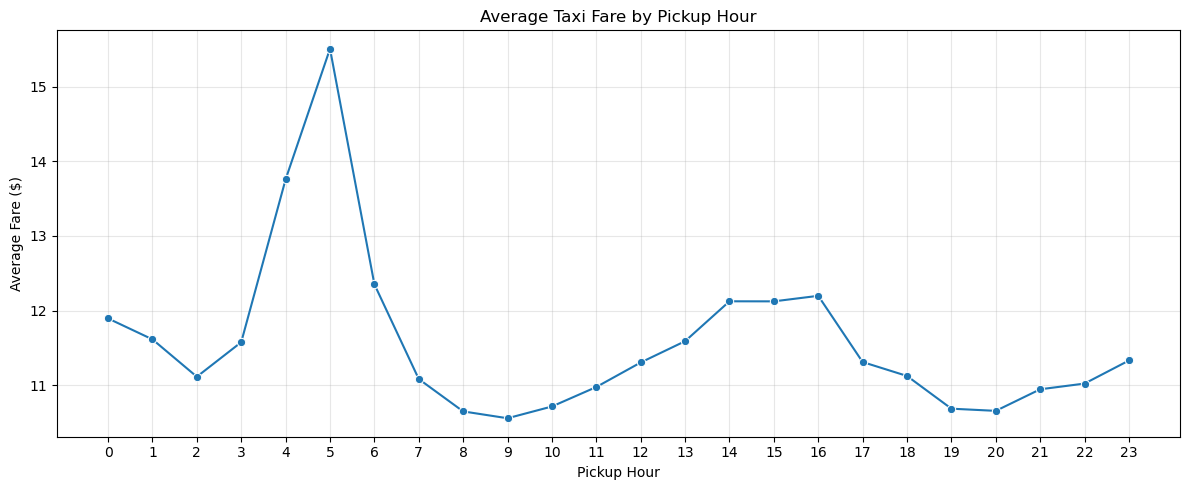

In [42]:
hourly_fare = df_model.groupby('pickup_hour')['amount'].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_fare.index,
    y=hourly_fare.values,
    marker='o'
)

plt.title("Average Taxi Fare by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Fare ($)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

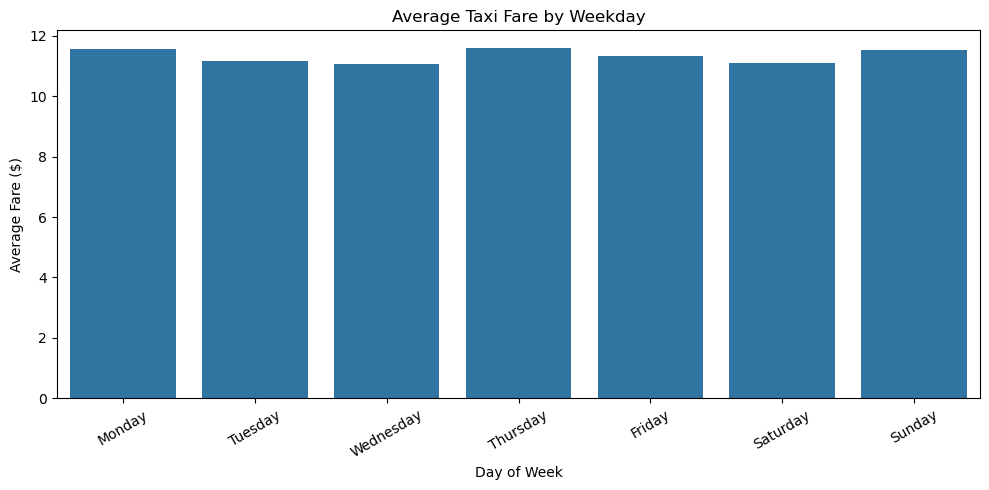

In [43]:
weekday_fare = df_model.groupby('pickup_weekday')['amount'].mean()

weekday_names = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_names,
    y=weekday_fare.values
)

plt.title("Average Taxi Fare by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Fare ($)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Average Weekday Fare: 11.340724857576365
Average Weekend Fare: 11.287560869565217


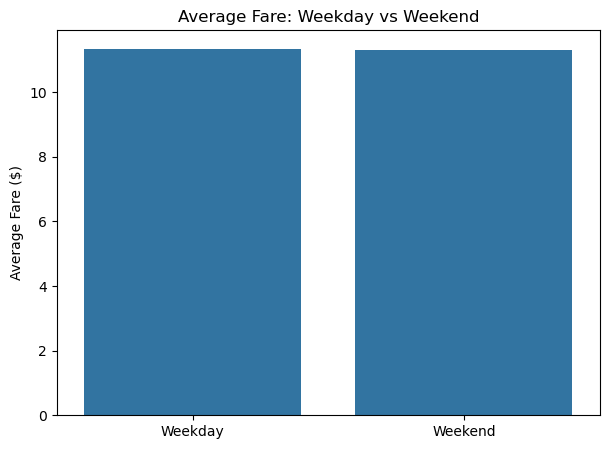

In [44]:
weekend_fare = df_model.groupby('is_weekend')['amount'].mean()

print("Average Weekday Fare:",
      weekend_fare[0])

print("Average Weekend Fare:",
      weekend_fare[1])

plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Weekday', 'Weekend'],
    y=[weekend_fare[0], weekend_fare[1]]
)

plt.title("Average Fare: Weekday vs Weekend")
plt.ylabel("Average Fare ($)")

plt.show()

              mean  median  count
pickup_hour                      
0            11.90     9.3   1845
1            11.62     9.0   1453
2            11.12     8.9   1058
3            11.58     8.9    819
4            13.76    10.1    593
5            15.51     9.3    493
6            12.35     7.7    991
7            11.08     8.0   1851
8            10.65     8.1   2154
9            10.56     8.1   2321
10           10.72     8.1   2215
11           10.98     8.5   2309
12           11.31     8.5   2403
13           11.59     8.5   2406
14           12.13     8.5   2414
15           12.12     8.5   2309
16           12.20     8.1   1997
17           11.31     8.5   2417
18           11.13     8.5   3012
19           10.69     8.1   3025
20           10.66     8.1   2783
21           10.95     8.5   2737
22           11.02     8.5   2725
23           11.33     8.5   2401


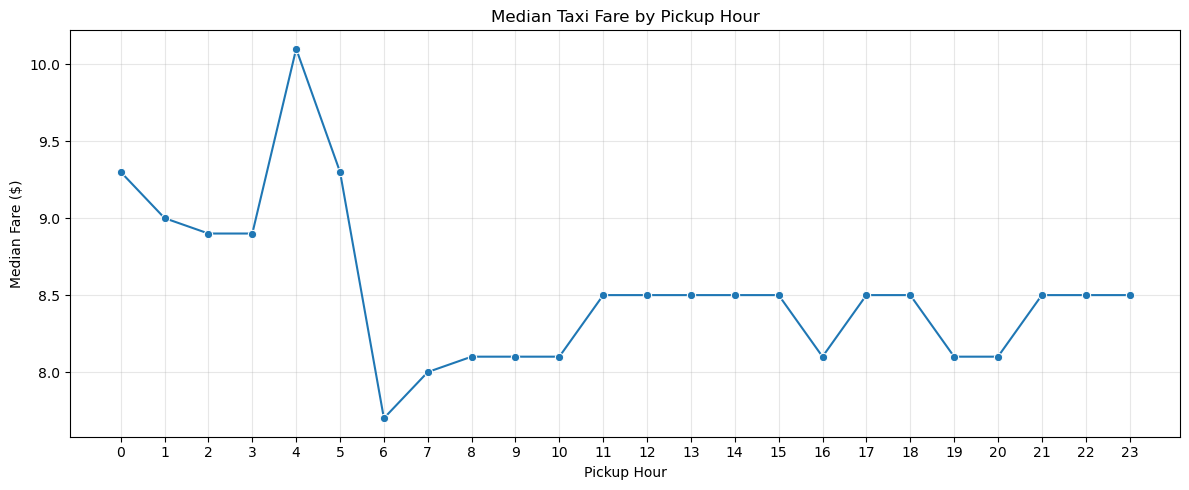

In [45]:
# Compare average fare, median fare and trip count by hour

hour_analysis = df_model.groupby('pickup_hour')['amount'].agg(
    ['mean', 'median', 'count']
)

print(hour_analysis.round(2))

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_analysis,
    x=hour_analysis.index,
    y='median',
    marker='o'
)

plt.title("Median Taxi Fare by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Median Fare ($)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
# Define model input features
features = [
    'longitude_of_pickup',
    'latitude_of_pickup',
    'longitude_of_dropoff',
    'latitude_of_dropoff',
    'no_of_passenger',
    'trip_distance',
    'pickup_hour',
    'pickup_day',
    'pickup_month',
    'pickup_weekday',
    'is_weekend',
    'is_night'
]

# Input variables
X = df_model[features]

# Target variable
y = df_model['amount']

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:", y.name)

Input Shape: (48731, 12)
Target Shape: (48731,)

Input Features:
['longitude_of_pickup', 'latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff', 'no_of_passenger', 'trip_distance', 'pickup_hour', 'pickup_day', 'pickup_month', 'pickup_weekday', 'is_weekend', 'is_night']

Target Variable: amount


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (38984, 12)
Testing Features: (9747, 12)
Training Target: (38984,)
Testing Target: (9747,)


In [48]:
print("Training percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining target statistics:")
display(y_train.describe())

print("\nTesting target statistics:")
display(y_test.describe())

Training percentage: 80.0 %
Testing percentage: 20.0 %

Training target statistics:


count    38984.000000
mean        11.300045
std          9.351251
min          0.010000
25%          6.000000
50%          8.500000
75%         12.500000
max        104.670000
Name: amount, dtype: float64


Testing target statistics:


count    9747.000000
mean       11.428158
std         9.526672
min         2.500000
25%         6.000000
50%         8.500000
75%        12.900000
max       103.000000
Name: amount, dtype: float64

In [49]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [50]:
# Create Machine Learning pipeline

rf_model = Pipeline([

    # Feature scaling
    ('scaler', StandardScaler()),

    # Random Forest Regressor
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [51]:
# Train Random Forest model

print("Training Random Forest Model...")

rf_model.fit(X_train, y_train)

print("\nModel training completed successfully!")

Training Random Forest Model...

Model training completed successfully!


In [52]:
# Predict taxi fares
y_pred = rf_model.predict(X_test)

print("Predictions completed successfully!")

# Display first 10 predictions
prediction_results = pd.DataFrame({
    'Actual Fare': y_test.values[:10],
    'Predicted Fare': y_pred[:10]
})

display(prediction_results.round(2))

Predictions completed successfully!


,Actual Fare,Predicted Fare
0,10.50,14.49
1,30.83,31.18
2,7.70,9.10
3,3.70,5.37
4,15.30,9.89
5,10.50,8.83
6,12.00,9.68
7,9.50,9.24
8,10.50,12.69
9,7.30,10.19


In [53]:
# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("RANDOM FOREST REGRESSION - EVALUATION")
print("--------------------------------------")

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

RANDOM FOREST REGRESSION - EVALUATION
--------------------------------------
MAE  : 2.1489
MSE  : 16.3723
RMSE : 4.0463
R2   : 0.8196


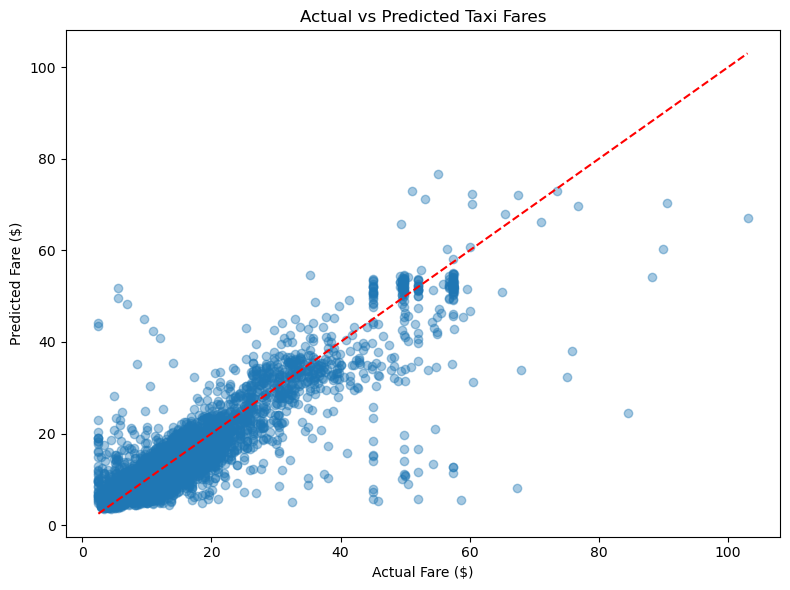

In [54]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted Taxi Fares")
plt.xlabel("Actual Fare ($)")
plt.ylabel("Predicted Fare ($)")

plt.tight_layout()
plt.show()

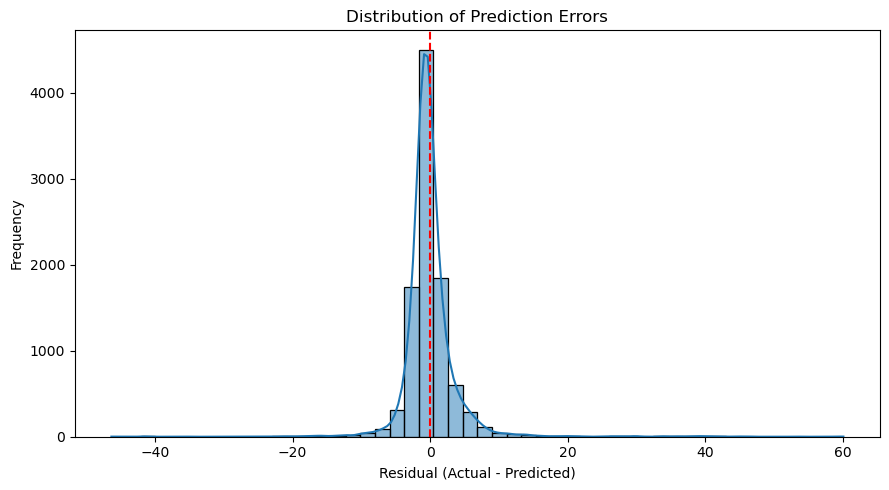

In [55]:
residuals = y_test.values - y_pred

plt.figure(figsize=(9, 5))

sns.histplot(residuals, bins=50, kde=True)

plt.axvline(0, color='red', linestyle='--')

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [56]:
RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [57]:
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [10, 15],
    'regressor__min_samples_split': [2, 5]
}

print("Hyperparameter grid:")
print(param_grid)

Hyperparameter grid:
{'regressor__n_estimators': [100, 200], 'regressor__max_depth': [10, 15], 'regressor__min_samples_split': [2, 5]}


In [58]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=1,
    verbose=2
)

print("GridSearchCV configured successfully!")

GridSearchCV configured successfully!


In [59]:
print("Starting GridSearchCV...")

grid_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed!")

Starting GridSearchCV...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=100; total time=   2.8s
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=100; total time=   2.7s
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=100; total time=   2.7s
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=200; total time=   5.3s
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=200; total time=   5.4s
[CV] END regressor__max_depth=10, regressor__min_samples_split=2, regressor__n_estimators=200; total time=   5.2s
[CV] END regressor__max_depth=10, regressor__min_samples_split=5, regressor__n_estimators=100; total time=   3.5s
[CV] END regressor__max_depth=10, regressor__min_samples_split=5, regressor__n_estimators=100; total time=   3.5s
[CV

In [60]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-grid_search.best_score_)

Best Parameters:
{'regressor__max_depth': 15, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 200}

Best Cross-Validation MAE:
2.1105599963913444


In [61]:
# Retrieve best model
best_model = grid_search.best_estimator_

# Predict test data
y_pred_tuned = best_model.predict(X_test)

# Calculate metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)

tuned_mse = mean_squared_error(y_test, y_pred_tuned)

tuned_rmse = np.sqrt(tuned_mse)

tuned_r2 = r2_score(y_test, y_pred_tuned)

print("TUNED RANDOM FOREST PERFORMANCE")
print("--------------------------------")

print(f"MAE  : {tuned_mae:.4f}")
print(f"MSE  : {tuned_mse:.4f}")
print(f"RMSE : {tuned_rmse:.4f}")
print(f"R2   : {tuned_r2:.4f}")

TUNED RANDOM FOREST PERFORMANCE
--------------------------------
MAE  : 2.1354
MSE  : 16.2539
RMSE : 4.0316
R2   : 0.8209


In [62]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Baseline Model': [mae, mse, rmse, r2],
    'Tuned Model': [
        tuned_mae,
        tuned_mse,
        tuned_rmse,
        tuned_r2
    ]
})

display(comparison.round(4))

,Metric,Baseline Model,Tuned Model
0,MAE,2.1489,2.1354
1,MSE,16.3723,16.2539
2,RMSE,4.0463,4.0316
3,R2 Score,0.8196,0.8209


In [63]:
from sklearn.model_selection import cross_val_score

# Five-fold cross-validation using tuned model
cv_mae_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Convert negative MAE to positive
cv_mae_scores = -cv_mae_scores

print("Five-fold CV MAE Scores:")
print(cv_mae_scores)

print("\nMean CV MAE:",
      cv_mae_scores.mean())

print("Standard Deviation:",
      cv_mae_scores.std())

Five-fold CV MAE Scores:
[2.06564894 2.0868681  2.15109019 2.12336565 2.06481008]

Mean CV MAE: 2.0983565911485433
Standard Deviation: 0.03386275196198951


In [64]:
# Extract trained Random Forest model
rf = best_model.named_steps['regressor']

# Get feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df.round(4))

,Feature,Importance
5,trip_distance,0.8541
2,longitude_of_dropoff,0.0461
0,longitude_of_pickup,0.0262
3,latitude_of_dropoff,0.0236
1,latitude_of_pickup,0.0149
6,pickup_hour,0.0109
7,pickup_day,0.0084
8,pickup_month,0.0068
9,pickup_weekday,0.0048
4,no_of_passenger,0.0023


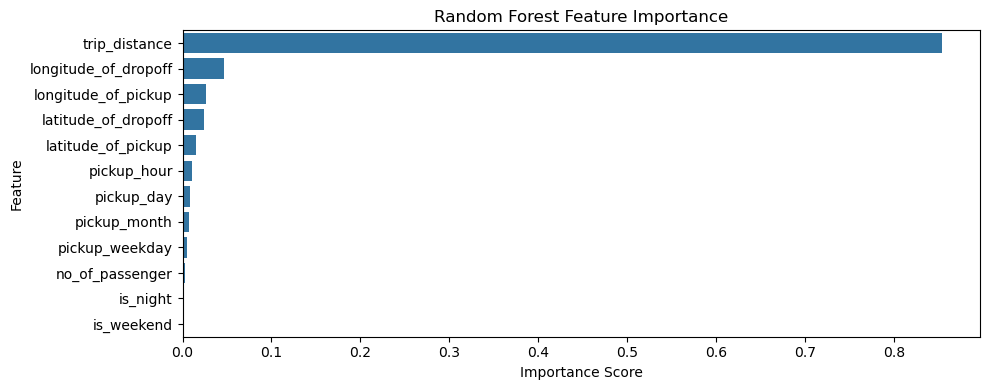

In [67]:
plt.figure(figsize=(10, 4))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
final_predictions = pd.DataFrame({
    'Actual Fare': y_test.iloc[:15].values,
    'Predicted Fare': y_pred_tuned[:15]
})

final_predictions['Absolute Error'] = abs(
    final_predictions['Actual Fare'] -
    final_predictions['Predicted Fare']
)

display(final_predictions.round(2))

,Actual Fare,Predicted Fare,Absolute Error
0,10.50,14.39,3.89
1,30.83,31.44,0.61
2,7.70,10.17,2.47
3,3.70,5.57,1.87
4,15.30,10.12,5.18
5,10.50,8.96,1.54
6,12.00,9.67,2.33
7,9.50,9.01,0.49
8,10.50,11.80,1.30
9,7.30,10.05,2.75


In [68]:
import joblib

# Save the best tuned Random Forest pipeline
joblib.dump(best_model, 'taxi_fare_random_forest.pkl')

print("Model saved successfully!")

Model saved successfully!


In [69]:
# Load saved model
loaded_model = joblib.load('taxi_fare_random_forest.pkl')

# Predict using loaded model
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Predictions using saved model:")
print(sample_prediction)

print("\nOriginal predictions:")
print(y_pred_tuned[:5])

Predictions using saved model:
[14.38938806 31.44247535 10.16568049  5.57236739 10.11802664]

Original predictions:
[14.38938806 31.44247535 10.16568049  5.57236739 10.11802664]


In [70]:
# Save actual and predicted fares
final_results = pd.DataFrame({
    'Actual_Fare': y_test.values,
    'Predicted_Fare': y_pred_tuned
})

final_results['Absolute_Error'] = abs(
    final_results['Actual_Fare'] -
    final_results['Predicted_Fare']
)

final_results.to_csv(
    'taxi_fare_predictions.csv',
    index=False
)

print("Prediction results exported successfully!")

Prediction results exported successfully!


In [71]:
import os
import joblib
import numpy as np
import pandas as pd

print("=" * 50)
print("TAXI FARE PREDICTION - FINAL VALIDATION")
print("=" * 50)

# 1. Dataset validation
print("\n1. DATASET")
print("Shape:", df_model.shape)
print("Missing values:", df_model.isnull().sum().sum())
print("Duplicate rows:", df_model.duplicated().sum())

# 2. Feature validation
print("\n2. FEATURE VALIDATION")
print("Expected features:", len(features))
print("Actual features:", X.shape[1])
print("Target:", y.name)

# 3. Train-test validation
print("\n3. TRAIN-TEST SPLIT")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

# 4. Model validation
print("\n4. MODEL")
print("Best parameters:", grid_search.best_params_)
print("Estimator:", best_model.named_steps['regressor'])

# 5. Prediction validation
print("\n5. PREDICTIONS")
print("Prediction count:", len(y_pred_tuned))
print("Actual count:", len(y_test))
print("Missing predictions:", np.isnan(y_pred_tuned).sum())

# 6. Evaluation metrics
print("\n6. MODEL PERFORMANCE")
print(f"MAE:  {tuned_mae:.4f}")
print(f"MSE:  {tuned_mse:.4f}")
print(f"RMSE: {tuned_rmse:.4f}")
print(f"R2:   {tuned_r2:.4f}")

# 7. Saved file validation
print("\n7. EXPORTED FILES")

files = [
    'taxi_fare_random_forest.pkl',
    'taxi_fare_predictions.csv'
]

for file in files:
    print(file, ":", "FOUND" if os.path.exists(file) else "MISSING")

# 8. Reload model verification
loaded_model = joblib.load('taxi_fare_random_forest.pkl')

check_predictions = loaded_model.predict(X_test.iloc[:5])

print("\n8. SAVED MODEL VERIFICATION")
print("Predictions match:",
      np.allclose(check_predictions, y_pred_tuned[:5]))

print("\nFINAL VALIDATION COMPLETED")

TAXI FARE PREDICTION - FINAL VALIDATION

1. DATASET
Shape: (48731, 14)
Missing values: 0
Duplicate rows: 0

2. FEATURE VALIDATION
Expected features: 12
Actual features: 12
Target: amount

3. TRAIN-TEST SPLIT
Training: (38984, 12)
Testing: (9747, 12)

4. MODEL
Best parameters: {'regressor__max_depth': 15, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 200}
Estimator: RandomForestRegressor(max_depth=15, min_samples_split=5, n_estimators=200,
                      n_jobs=-1, random_state=42)

5. PREDICTIONS
Prediction count: 9747
Actual count: 9747
Missing predictions: 0

6. MODEL PERFORMANCE
MAE:  2.1354
MSE:  16.2539
RMSE: 4.0316
R2:   0.8209

7. EXPORTED FILES
taxi_fare_random_forest.pkl : FOUND
taxi_fare_predictions.csv : FOUND

8. SAVED MODEL VERIFICATION
Predictions match: True

FINAL VALIDATION COMPLETED
